# H2: why the correction-summary plot (F6) shows less improvement than the DCR plot (internal, not for the paper)

Each Gaia-star epoch's offset from Gaia is split into the component **along** the parallactic direction (where DCR
acts) and **across** it. For each correction stage: the *systematic* DCR signal (RMS of binned medians in cells of
colour x airmass -- what F2/F3 show), the *scatter* along and across, and the *total* 2-D median offset (what F6
shows). Gaia stars, sigma < 10 mas, slice 000 (`py_files/dcr_fit.load_stage_sample`).

In [1]:
import os, sys
import numpy as np
import matplotlib.pyplot as plt
sys.path.append(os.path.abspath('..'))
from py_files import dcr_fit, plot_style as ps
ps.apply()
OUT = 'plots/'
S = dcr_fit.load_stage_sample(['000'])
rs = lambda v: 1.4826 * np.median(np.abs(v - np.median(v)))
C_EDGES = np.linspace(-2, 3, 26); T_EDGES = np.array([0, 0.1, 0.2, 0.3, 0.45, 0.6, 0.8, 1.0, 1.3])
STAGES = [('raw', 'raw'), ('dcr', '+ DCR'), ('rm', '+ CCD maps'), ('lm', '+ lateral')]
METRICS = ['systematic along par.', 'scatter along par.', 'scatter across par.', 'total 2-D median']
R = {}
for b in 'griz':
    m = (S['band'] == b) & np.isfinite(S['c_rel'])
    for st, _ in STAGES:
        cells = dcr_fit.binned_2d(S['c_rel'][m], S['tanz'][m], S[f'par_{st}'][m], C_EDGES, T_EDGES)
        w = 1 / cells[3]**2
        R[b, st] = [np.sqrt(np.sum(w * cells[2]**2) / np.sum(w)), rs(S[f'par_{st}'][m]), rs(S[f'perp_{st}'][m]),
                    np.median(np.hypot(S[f'par_{st}'][m], S[f'perp_{st}'][m]))]
for b in 'griz':
    print(b, {st: np.round(R[b, st], 2).tolist() for st, _ in STAGES})

g {'raw': [17.12, 24.7, 13.02, 22.66], 'dcr': [3.71, 15.89, 13.02, 17.13], 'rm': [4.22, 18.62, 16.09, 20.48], 'lm': [3.87, 17.87, 15.52, 19.72]}
r {'raw': [6.14, 15.21, 11.94, 16.02], 'dcr': [2.03, 13.56, 11.94, 15.07], 'rm': [2.04, 13.0, 11.42, 14.27], 'lm': [1.89, 12.91, 11.38, 14.2]}
i {'raw': [3.18, 13.81, 12.25, 15.34], 'dcr': [2.53, 13.61, 12.25, 15.23], 'rm': [2.56, 12.73, 11.39, 14.04], 'lm': [2.42, 12.76, 11.5, 14.12]}
z {'raw': [1.05, 12.2, 11.12, 13.74], 'dcr': [0.8, 12.16, 11.12, 13.72], 'rm': [0.69, 11.76, 10.79, 13.11], 'lm': [0.69, 11.76, 10.78, 13.11]}


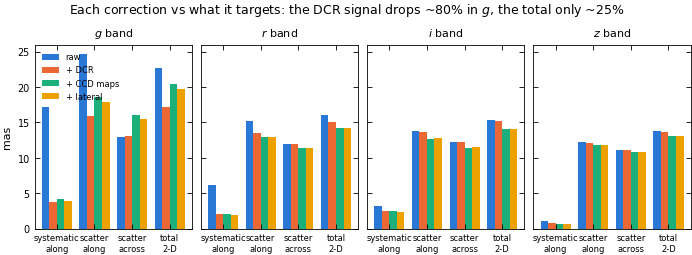

In [2]:
fig, axes = plt.subplots(1, 4, figsize=(ps.PAGE, 2.6), sharey=True, constrained_layout=True)
xx = np.arange(len(METRICS))
for ax, b in zip(axes, 'griz'):
    for k, (st, label) in enumerate(STAGES):
        ax.bar(xx + 0.2 * (k - 1.5), R[b, st], width=0.2, color=ps.SERIES[k], label=label)
    ax.set_xticks(xx, ['systematic\nalong', 'scatter\nalong', 'scatter\nacross', 'total\n2-D'], fontsize=6)
    ax.set_title(f'${b}$ band')
axes[0].set_ylabel('mas'); axes[0].legend(fontsize=6)
fig.suptitle('Each correction vs what it targets: the DCR signal drops ~80% in $g$, the total only ~25%')
plt.savefig(OUT + 'h2_components_by_stage.pdf')